# 第 15 步：完整历史回测与四项绩效指标

<!-- SNAPSHOT_NOTE -->

## 数据准备说明

本页记录完整快照上的实际运行。通过 GitHub 克隆源码后，先在仓库根目录运行 `python publication/restore_snapshot.py`，恢复同版本的 `data/` 与 `runs/`，再执行本步。[完整数据与大型结果索引](../../publication/ASSET_INDEX.md)保留全部路径和哈希；本页图表与 Notebook 已保存输出可直接阅读。

## 目标与研究范围

前两步已经核对首次成交和第二次调仓。本步沿用相同因子、方向、目标组合与成交规则，把账户从 2020-01-01 连续运行到 2025-12-31，再从已实现的每日账户收益计算累计收益、复合年化收益、年化波动和最大回撤。参数保持不变，不因曲线好坏调整；盈利或亏损本身也不能证明程序正确。

本步使用 40 只人工股票。输入从 2019 年开始，为滚动窗口提供历史；正式账户从 2020 年开始。日历使用工作日，包含现实市场假日，因此图表和表格都明确限定为模拟历史，不作完整 A 股实证解释。

## 前置文件与运行命令

在仓库根目录使用已安装的独立环境运行：

```powershell
.\.venv\Scripts\python.exe examples/15_full_history_performance.py
```

输入是 [固定模拟快照](../../runs/first_demo_20261107/input/metadata.json) 和 [baseline.json](../../configs/baseline.json)。本步脚本重新计算滚动因子并运行核心引擎，不依赖终端中手工保留的变量。如果第 14 步的 `daily.csv` 存在，脚本会检查重叠区间是否一致。这样，第 14 步也成为局部审计样本，可以发现扩展历史后首次买入或第二次调仓是否发生变化。

主要输出是 [summary.json](../../runs/first_demo_20261107/lesson15_full_backtest/summary.json)、[daily.csv](../../runs/first_demo_20261107/lesson15_full_backtest/daily.csv) 和 [metrics.csv](../../runs/first_demo_20261107/lesson15_full_backtest/metrics.csv)。成交、订单和持仓也一同保存，使每个指标都能回到对应账户记录。

![完整模拟净值与回撤](../../runs/first_demo_20261107/lesson15_full_backtest/full_history_nav_drawdown.png)

图的上半部分展示账户净值与截至当日的历史高点，下半部分展示相对于各自历史高点的回撤。曲线每个点都是收盘估值，期末也仍有持仓，不是强制清仓后的现金。

## 账户首条收益为什么不是缺失值

前面单只股票的第一天日收益没有前一价格，保留 `NaN` 是正确做法；本步账户的第一条收益含义不同。账户在开始前有已知初始资金 (E_0=1,000,000)，因此第一条收益可以定义为第一收盘权益除以初始资金减一。

本次 2020-01-01 仍为持币状态，权益 100 万、净值 1、日收益 0。首次执行在 2020-02-03，之前共有 23 个模拟持币日，都属于已经声明的评价区间。这些零收益日需要保留；以“还没买股票”为由删除，会改变年化天数、平均收益和波动估计。

账户收益以核心 `daily["return"]` 为准，不在切片后重新 `pct_change()` 再把第一行填零。若首日发生费用或亏损，强行置零会漏掉这部分损益。本次首行为零只是实际持币结果，不是通用修补规则。

## 四项指标的公式与代码

### 累计财富：连乘简单收益的增长倍数

设每日简单收益率为 (r_t)，起始财富为 1：

$$
W_t=\prod_{u=1}^{t}(1+r_u),\qquad R_{total}=W_T-1.
$$

```python
returns = daily["return"].astype(float)
daily["growth_factor"] = 1 + returns
daily["nav_from_returns"] = daily["growth_factor"].cumprod(skipna=False)
daily["cumulative_return"] = daily["nav_from_returns"] - 1
```

第一行明确数值类型，第二行把收益变成财富增长倍数，第三行按时间顺序连乘，第四行转换为累计收益。`skipna=False` 保证中途未知收益不会被跳过；脚本还在计算前拒绝缺失、无穷和不大于 -100% 的非法收益。

连乘净值需要同时等于 `daily.nav` 和 `equity / initial_cash`。三种口径的差异只能在浮点尾数范围，不能只因最终值碰巧相同就忽略中间路径。

### 复合年化：明确采用 252 交易日口径

设收益条数为 (N)，一年约定为 252 个交易日：

$$
R_{annual}=W_T^{252/N}-1.
$$

```python
n_days = len(returns)
annual_return = (1 + total_return) ** (annual_sessions / n_days) - 1
```

本次有 1566 条账户日收益，折合 (1566/252=6.2142857143) 个约定交易年。它不等同于两个日期之间的自然年长度，因此结果标为“252 交易日口径复合年化”，避免与自然年 CAGR 混用。日收益算术均值乘 252 也不等于这个复合增长率；前者不反映相同的财富连乘结果。

### 年化波动：从样本日标准差出发

$$
s_r=\sqrt{\frac{1}{N-1}\sum_{t=1}^{N}(r_t-\bar r)^2},
\qquad \sigma_{annual}=s_r\sqrt{252}.
$$

```python
daily_volatility = returns.std(ddof=1)
annual_volatility = daily_volatility * np.sqrt(annual_sessions)
```

第一行明确 `ddof=1`，分母为 (N-1)；第二行采用平方根时间的年化约定。净值序列的标准差不能代替日收益波动，乘 252 与乘 $\sqrt{252}$ 也有不同含义。这个年化指标是研究中的统一刻度，不是对任意长周期风险的精确预测。

### 回撤：比较截至当日的历史高点

$$
H_t=\max(1,W_1,\ldots,W_t),\quad
DD_t=W_t/H_t-1\leq0,\quad MDD=-\min_tDD_t.
$$

```python
daily["running_peak"] = daily["nav_from_returns"].cummax(skipna=False).clip(lower=1.0)
daily["drawdown"] = daily["nav_from_returns"] / daily["running_peak"] - 1
max_drawdown_signed = daily["drawdown"].min()
max_drawdown = -max_drawdown_signed
```

`cummax` 保证高点只来自当前及以前；`clip(lower=1)` 把最初的财富 1 纳入比较。若开局净值跌至 0.9，历史高点仍应为 1，否则会漏掉第一笔 10% 回撤。核心函数保存负的 `max_drawdown`，本课展示正的“回撤幅度”，同时保留两个字段以明确符号。

不能使用 `nav.max()` 作为整段统一分母，因为未来才出现的高点不能成为过去的回撤基准。例如路径 `[1, 0.5, 2]` 的最大回撤是 50%，用未来全局最高 2 衡量中间的 0.5 会错误得到 75%。最大回撤也不是单日收益最低值，连续多天小幅下跌同样能形成较深回撤。

## 四项指标与账户终值

以下数字来自本步保存的 `summary.json`，不是预设目标：

| 指标 | 实际模拟输出 |
| --- | ---: |
| 账户日收益条数 | 1566 |
| 累计收益 | -3.5632008619% |
| 252 日口径复合年化收益 | -0.5821523681% |
| 样本日波动率 | 0.8568048424% |
| 年化波动率 | 13.6013552102% |
| 最大回撤幅度 | 29.7749829903% |
| 期末净值 | 0.964367991381 |
| 期末权益 | 964367.9913810544 |
| 期末现金 | 98545.52059094235 |
| 期末股票数量 | 9 |
| 累计经济交易成本 | 93205.4194780295 |
| 有成交的执行日 / 成交笔数 | 71 / 1164 |

最深回撤从 2020-12-28 的峰值净值 `1.089308947508`，下降到 2025-02-28 的 `0.764967393675`。峰值从谷底之前的切片查找，不能在谷底之后另选更高日期。到期末尚未恢复这个高点，期末回撤约为 -11.4697%；它既不是累计收益 -3.5632%，也不是最大回撤幅度 29.7750%。三个数字使用的比较基准不同。

最后一次执行发生在 2025-12-01，最后一行只是 2025-12-31 收盘标记。现金与九只股票的市值共同组成终值，没有增加末日清仓交易，也没有收取假设的退出费用。

## 从指标回到账户审计

账户审计检查 `equity = cash + market_value.sum()` 在每个日期成立、现金不为负、每笔成交严格晚于对应信号。同时，第 15 步在第 14 步已有的 22 个日期上逐列核对，确认完整运行没有改写早期账户。

`daily.csv` 同时保留原始账户列与新增过程列：`growth_factor`、`nav_from_returns`、`cumulative_return`、`running_peak`、`drawdown`。前四项基础列 `nav/cash/equity/return` 可以还原资金和收益，新增列可以逐行解释四指标，核对过程不只依赖最终一行汇总。

计算终值或累计收益时，不再减去 `total_cost`。佣金、税费和滑点已经通过成交价、现金与持仓数量进入账户收益；汇总成本是审计字段，不是等待第二次扣除的账单。

解释终值时，也需要查看现金占比。最后的约 9.85 万元现金属于账户资产，既不能从权益中删除，也不能假定它像股票一样产生了收益。本教学引擎没有给现金计息；若以后加入货币收益，需要单独明确现金收益规则，不能在计算年化时临时补上一段利息。

完整历史也不等于足够可靠的研究结论。六年模拟长度让程序经历了多次月末与跨年，但价格由固定随机种子生成，缺少真实市场的产业结构、制度演变和可投资性证据。对我而言，这些数据的作用是核对会计、时间和指标，曲线较长并不能赋予它超出来源的可信度。复合年化是这段已发生模拟路径的统一表达，不是对下一年的收益承诺。

## 验收、结论与下一步

本步验收包括：正式期间与配置相同；2019 年只作预热；23 个持币日和首行已知收益保留；财富连乘与账户净值一致；年化天数与标准差自由度明确；初始财富参加高点；峰值在谷底之前；期末估值与未清仓状态明确。波动、回撤和收益都应能从过程表复算。

据此只能判断这个固定模拟策略没有让初始资金增长，不能推断“量化无效”或“该因子在 A 股无效”。下一步引入定义清楚、费率相同的基准，并通过重新运行成本档位区分选股结果和交易摩擦的影响。

[完整脚本](../../examples/15_full_history_performance.py) · [下一步：基准与成本对照](../16_benchmark_cost_comparison/README.md)

## 完整可运行实现

上面的片段用于解释思路；下面各单元按顺序执行完整脚本。先定位仓库根目录，并显式设置脚本路径，使 `__file__` 在 Notebook 中也有明确含义。

In [1]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = next((candidate for candidate in [Path.cwd(), *Path.cwd().parents]
                     if (candidate / "pyproject.toml").exists()
                     and (candidate / "examples/01_read_prices.py").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("我需要从本项目目录或它的子目录打开 Notebook。")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
os.chdir(PROJECT_ROOT)
__file__ = str(PROJECT_ROOT / 'examples/15_full_history_performance.py')
sys.argv = [__file__]


### 完整实现 · 单元 1

In [2]:
r"""第十五课：完整历史回测，逐行计算收益、波动和回撤。

运行：.\.venv\Scripts\python.exe examples/15_full_history_performance.py
输入沿用 first_demo_20261107 的人工行情；不拼入第十四课的人为拒卖场景。
"""

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

from ashare_lab.backtest import metrics, run_backtest
from ashare_lab.config import load_config
from ashare_lab.data import load_dataset, write_json
from ashare_lab.factors import compute_factors

### 完整实现 · 单元 2

In [3]:
def calculate_performance(daily, initial_cash, annual_sessions=252):
    """返回带计算过程的日表和指标；金额不再重复扣除交易成本。"""
    daily = daily.copy().sort_values("date").reset_index(drop=True)
    if len(daily) < 2 or daily["date"].duplicated().any():
        raise ValueError("至少需要两个不同日期的账户记录。")
    if initial_cash <= 0 or annual_sessions <= 0:
        raise ValueError("初始资金和每年交易日数必须为正。")
    returns = daily["return"].astype(float)
    if not np.isfinite(returns).all() or (returns <= -1).any():
        raise ValueError("日收益缺失或非法；不能填零后继续计算。")

    # A. 净值与累计收益：每一行是账户的已知日收益，包括持币日。
    daily["growth_factor"] = 1 + returns
    daily["nav_from_returns"] = daily["growth_factor"].cumprod(skipna=False)
    daily["cumulative_return"] = daily["nav_from_returns"] - 1
    total_return = daily["cumulative_return"].iloc[-1]

    # B. 复合年化：把 n 个模拟交易日折算成 n / 252 个交易年。
    n_days = len(returns)
    annual_return = (1 + total_return) ** (annual_sessions / n_days) - 1

    # C. 样本日波动率及平方根时间法则下的年化波动率。
    daily_volatility = returns.std(ddof=1)
    annual_volatility = daily_volatility * np.sqrt(annual_sessions)

    # D. 初始净值 1 也参与历史高点，避免漏掉开局亏损。
    daily["running_peak"] = daily["nav_from_returns"].cummax(skipna=False).clip(lower=1.0)
    daily["drawdown"] = daily["nav_from_returns"] / daily["running_peak"] - 1
    max_drawdown_signed = daily["drawdown"].min()
    max_drawdown = -max_drawdown_signed

    # E. 定位最深回撤的谷底，以及谷底之前的历史峰值。
    trough_index = daily["drawdown"].idxmin()
    before_trough = daily.loc[:trough_index]
    peak_index = before_trough["nav_from_returns"].idxmax()
    peak_date = None
    peak_nav = 1.0
    if before_trough.loc[peak_index, "nav_from_returns"] >= 1:
        peak_date = str(before_trough.loc[peak_index, "date"].date())
        peak_nav = float(before_trough.loc[peak_index, "nav_from_returns"])

    # F. 三种口径交叉核对；不把首日收益强行设为零。
    np.testing.assert_allclose(daily["nav_from_returns"], daily["nav"], rtol=0, atol=1e-10)
    np.testing.assert_allclose(daily["nav_from_returns"], daily["equity"] / initial_cash,
                               rtol=0, atol=1e-10)
    core = metrics(daily)
    np.testing.assert_allclose(
        [total_return, annual_return, annual_volatility, max_drawdown_signed],
        [core["total_return"], core["annual_return"], core["annual_volatility"], core["max_drawdown"]],
        rtol=0, atol=1e-10,
    )

    summary = dict(
        source="synthetic teaching data; weekday calendar, not an A-share exchange calendar",
        start=str(daily["date"].iloc[0].date()), end=str(daily["date"].iloc[-1].date()),
        n_days=n_days, annual_sessions=annual_sessions,
        effective_trading_years=float(n_days / annual_sessions),
        initial_cash=float(initial_cash), final_equity=float(daily["equity"].iloc[-1]),
        final_nav=float(daily["nav_from_returns"].iloc[-1]),
        total_return=float(total_return), annual_return=float(annual_return),
        daily_volatility=float(daily_volatility), annual_volatility=float(annual_volatility),
        max_drawdown=float(max_drawdown), max_drawdown_signed=float(max_drawdown_signed),
        drawdown_peak_date=peak_date, drawdown_peak_nav=peak_nav,
        drawdown_trough_date=str(daily.loc[trough_index, "date"].date()),
        drawdown_trough_nav=float(daily.loc[trough_index, "nav_from_returns"]),
        final_drawdown=float(daily["drawdown"].iloc[-1]),
        total_cost=float(daily["cost"].sum()), final_cash=float(daily["cash"].iloc[-1]),
        final_holdings_count=int(daily["holdings_count"].iloc[-1]),
        terminal_valuation="last close; no hypothetical liquidation",
    )
    return daily, summary

### 完整实现 · 单元 3

In [4]:
def plot_performance(daily, summary, output_path):
    """上方净值、下方回撤，完整展示所有模拟交易日。"""
    plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
    plt.rcParams["axes.unicode_minus"] = False
    plt.rcParams["font.size"] = 11
    fig, (ax_nav, ax_dd) = plt.subplots(
        2, 1, figsize=(11.5, 7.8), sharex=True,
        gridspec_kw={"height_ratios": [2, 1]}, layout="constrained",
    )
    fig.suptitle("三因子策略：完整历史净值与回撤（模拟数据）", fontsize=17)
    ax_nav.set_title(
        f"2020—2025 年，含教学交易成本；累计收益 {summary['total_return']:.2%}",
        loc="left", fontsize=11, pad=12,
    )
    ax_nav.plot(daily["date"], daily["nav_from_returns"], color="#3268A8", linewidth=1.5,
                label="账户净值")
    ax_nav.plot(daily["date"], daily["running_peak"], color="#747D86", linestyle="--",
                linewidth=1.2, label="截至当日的历史高点")
    ax_nav.axhline(1, color="#9FA6AD", linestyle=":", linewidth=0.8)
    ax_nav.set_ylabel("净值（初始资金 = 1）")
    ax_nav.set_ylim(daily["nav_from_returns"].min() - 0.11, daily["nav_from_returns"].max() + 0.13)
    ax_nav.legend(loc="upper right", frameon=False, fontsize=10)
    if summary["drawdown_peak_date"] is not None:
        peak_date = pd.Timestamp(summary["drawdown_peak_date"])
        ax_nav.scatter(peak_date, summary["drawdown_peak_nav"], s=35, color="#3268A8", zorder=5)
        ax_nav.annotate(
            f"回撤前高 {peak_date:%Y-%m-%d}\n净值 {summary['drawdown_peak_nav']:.4f}",
            xy=(peak_date, summary["drawdown_peak_nav"]), xytext=(14, 27), textcoords="offset points",
            fontsize=10, arrowprops={"arrowstyle": "->", "color": "#747D86"},
        )
    trough_date = pd.Timestamp(summary["drawdown_trough_date"])
    ax_nav.scatter(trough_date, summary["drawdown_trough_nav"], marker="v", s=45,
                   color="#B46A31", zorder=5)
    ax_nav.annotate(
        f"回撤谷底 {trough_date:%Y-%m-%d}\n净值 {summary['drawdown_trough_nav']:.4f}",
        xy=(trough_date, summary["drawdown_trough_nav"]), xytext=(-165, -35), textcoords="offset points",
        fontsize=10, arrowprops={"arrowstyle": "->", "color": "#747D86"},
    )
    ax_nav.annotate(
        f"期末 {summary['final_nav']:.4f}", xy=(daily["date"].iloc[-1], summary["final_nav"]),
        xytext=(-100, 30), textcoords="offset points", fontsize=10,
        arrowprops={"arrowstyle": "->", "color": "#747D86"},
    )
    ax_dd.plot(daily["date"], daily["drawdown"], color="#3268A8", linewidth=1.1)
    ax_dd.fill_between(daily["date"], daily["drawdown"], 0, color="#3268A8", alpha=0.18)
    ax_dd.axhline(0, color="#747D86", linewidth=0.8)
    ax_dd.scatter(trough_date, summary["max_drawdown_signed"], marker="v", s=40,
                  color="#B46A31", zorder=5)
    ax_dd.annotate(
        f"最大回撤幅度 {summary['max_drawdown']:.2%}",
        xy=(trough_date, summary["max_drawdown_signed"]), xytext=(-60, -9),
        textcoords="offset points", ha="center", va="top", fontsize=10,
        arrowprops={"arrowstyle": "->", "color": "#747D86"},
    )
    ax_dd.set_ylim(summary["max_drawdown_signed"] - 0.055, 0.025)
    ax_dd.set_ylabel("相对历史高点的回撤")
    ax_dd.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ticks = pd.date_range(daily["date"].iloc[0], daily["date"].iloc[-1], freq="YS")
    ticks = ticks.union(pd.DatetimeIndex([daily["date"].iloc[0], daily["date"].iloc[-1]]))
    ax_dd.set_xticks(ticks)
    ax_dd.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
    ax_dd.set_xlim(daily["date"].iloc[0] - pd.Timedelta(days=20),
                   daily["date"].iloc[-1] + pd.Timedelta(days=20))
    ax_dd.set_xlabel("日期（模拟工作日日历；期末按收盘估值，仍有持仓）")
    for ax in (ax_nav, ax_dd):
        ax.grid(axis="y", color="#DCE2E8", linewidth=0.7)
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(axis="both", labelsize=10)
    fig.savefig(output_path, dpi=180)
    plt.close(fig)

### 完整实现 · 单元 4

In [5]:
def main():
    # 1. 定位项目与输入；不用重新生成数据，不改上一课文件。
    project_dir = Path(__file__).resolve().parents[1]
    run_dir = project_dir / "runs" / "first_demo_20261107"
    prices, universe, calendar, _ = load_dataset(run_dir / "input")

    # 2. 恢复完整区间；2019 年行情保留在 prices 中，只用于滚动历史预热。
    config = load_config(project_dir / "configs" / "baseline.json")
    config["calendar_dates"] = calendar.strftime("%Y-%m-%d").tolist()

    # 3. 沿用同一套因子与成交规则，连续运行 2020-01-01 到 2025-12-31。
    factors = compute_factors(prices, universe, config)
    result = run_backtest(prices, factors, calendar, config)

    # 4. 展开四项指标的计算过程。
    daily, summary = calculate_performance(result.daily, config["initial_cash"])

    # 5. 对账：每日权益包含现金与实际持仓；成交严格晚于信号。
    invested = result.positions.groupby("date")["market_value"].sum()
    stock_values = daily["date"].map(invested).fillna(0)
    np.testing.assert_allclose(daily["equity"], daily["cash"] + stock_values, rtol=0, atol=1e-7)
    assert (daily["cash"] >= 0).all()
    assert (result.trades["date"] > result.trades["signal_date"]).all()
    summary["execution_days_with_trades"] = int(result.trades["date"].nunique())
    summary["trade_count"] = len(result.trades)
    summary["rejected_orders"] = int(result.orders["status"].eq("rejected").sum())

    # 6. 若上一课文件存在，核对重叠区间完全衔接。
    previous_path = run_dir / "lesson14_daily_rebalance" / "daily.csv"
    if previous_path.exists():
        previous = pd.read_csv(previous_path, parse_dates=["date"])
        current = daily.loc[daily["date"].isin(previous["date"]), previous.columns].reset_index(drop=True)
        pd.testing.assert_frame_equal(current, previous, check_exact=False, rtol=0, atol=1e-8)

    # 7. 独立保存本课结果；百分比仍存为小数，显示时才格式化。
    output_dir = run_dir / "lesson15_full_backtest"
    output_dir.mkdir(parents=True, exist_ok=True)
    daily.to_csv(output_dir / "daily.csv", index=False, date_format="%Y-%m-%d")
    for name in ["trades", "orders", "positions"]:
        getattr(result, name).to_csv(output_dir / f"{name}.csv", index=False, date_format="%Y-%m-%d")
    metric_names = ["total_return", "annual_return", "annual_volatility", "max_drawdown"]
    pd.DataFrame([{name: summary[name] for name in metric_names}]).to_csv(output_dir / "metrics.csv", index=False)
    write_json(output_dir / "summary.json", summary)
    write_json(output_dir / "config_snapshot.json", {k: v for k, v in config.items() if k != "calendar_dates"})
    plot_performance(daily, summary, output_dir / "full_history_nav_drawdown.png")

    print("人工行情与工作日日历；2019 年预热，2020—2025 年连续回测。")
    print(f"账户日收益条数：{summary['n_days']}；252 日口径年数：{summary['effective_trading_years']:.6f}")
    print(f"累计收益：{summary['total_return']:.6%}")
    print(f"复合年化收益（252 日口径）：{summary['annual_return']:.6%}")
    print(f"日波动率（样本标准差）：{summary['daily_volatility']:.6%}")
    print(f"年化波动率：{summary['annual_volatility']:.6%}")
    print(f"最大回撤幅度（正数）：{summary['max_drawdown']:.6%}")
    print(f"回撤峰值：{summary['drawdown_peak_date']}，净值 {summary['drawdown_peak_nav']:.9f}")
    print(f"回撤谷底：{summary['drawdown_trough_date']}，净值 {summary['drawdown_trough_nav']:.9f}")
    print(f"期末权益：{summary['final_equity']:,.6f}；期末净值：{summary['final_nav']:.9f}")
    print(f"期末现金：{summary['final_cash']:,.6f}；股票数量：{summary['final_holdings_count']}")
    print(f"有成交的执行日：{summary['execution_days_with_trades']}；成交笔数：{summary['trade_count']}")
    print("本课结果目录：", output_dir)

### 完整实现 · 单元 5

In [6]:
if __name__ == "__main__":
    main()

人工行情与工作日日历；2019 年预热，2020—2025 年连续回测。
账户日收益条数：1566；252 日口径年数：6.214286
累计收益：-3.563201%
复合年化收益（252 日口径）：-0.582152%
日波动率（样本标准差）：0.856805%
年化波动率：13.601355%
最大回撤幅度（正数）：29.774983%
回撤峰值：2020-12-28，净值 1.089308948
回撤谷底：2025-02-28，净值 0.764967394
期末权益：964,367.991381；期末净值：0.964367991
期末现金：98,545.520591；股票数量：9
有成交的执行日：71；成交笔数：1164
本课结果目录： .\runs\first_demo_20261107\lesson15_full_backtest


## 图表输出

完整脚本已经保存图表。这里把本步或正文明确引用的跨步图表显示为静态输出，因此 GitHub 页面无需活动内核也能看到图片。数值与图表来源沿用正文说明。

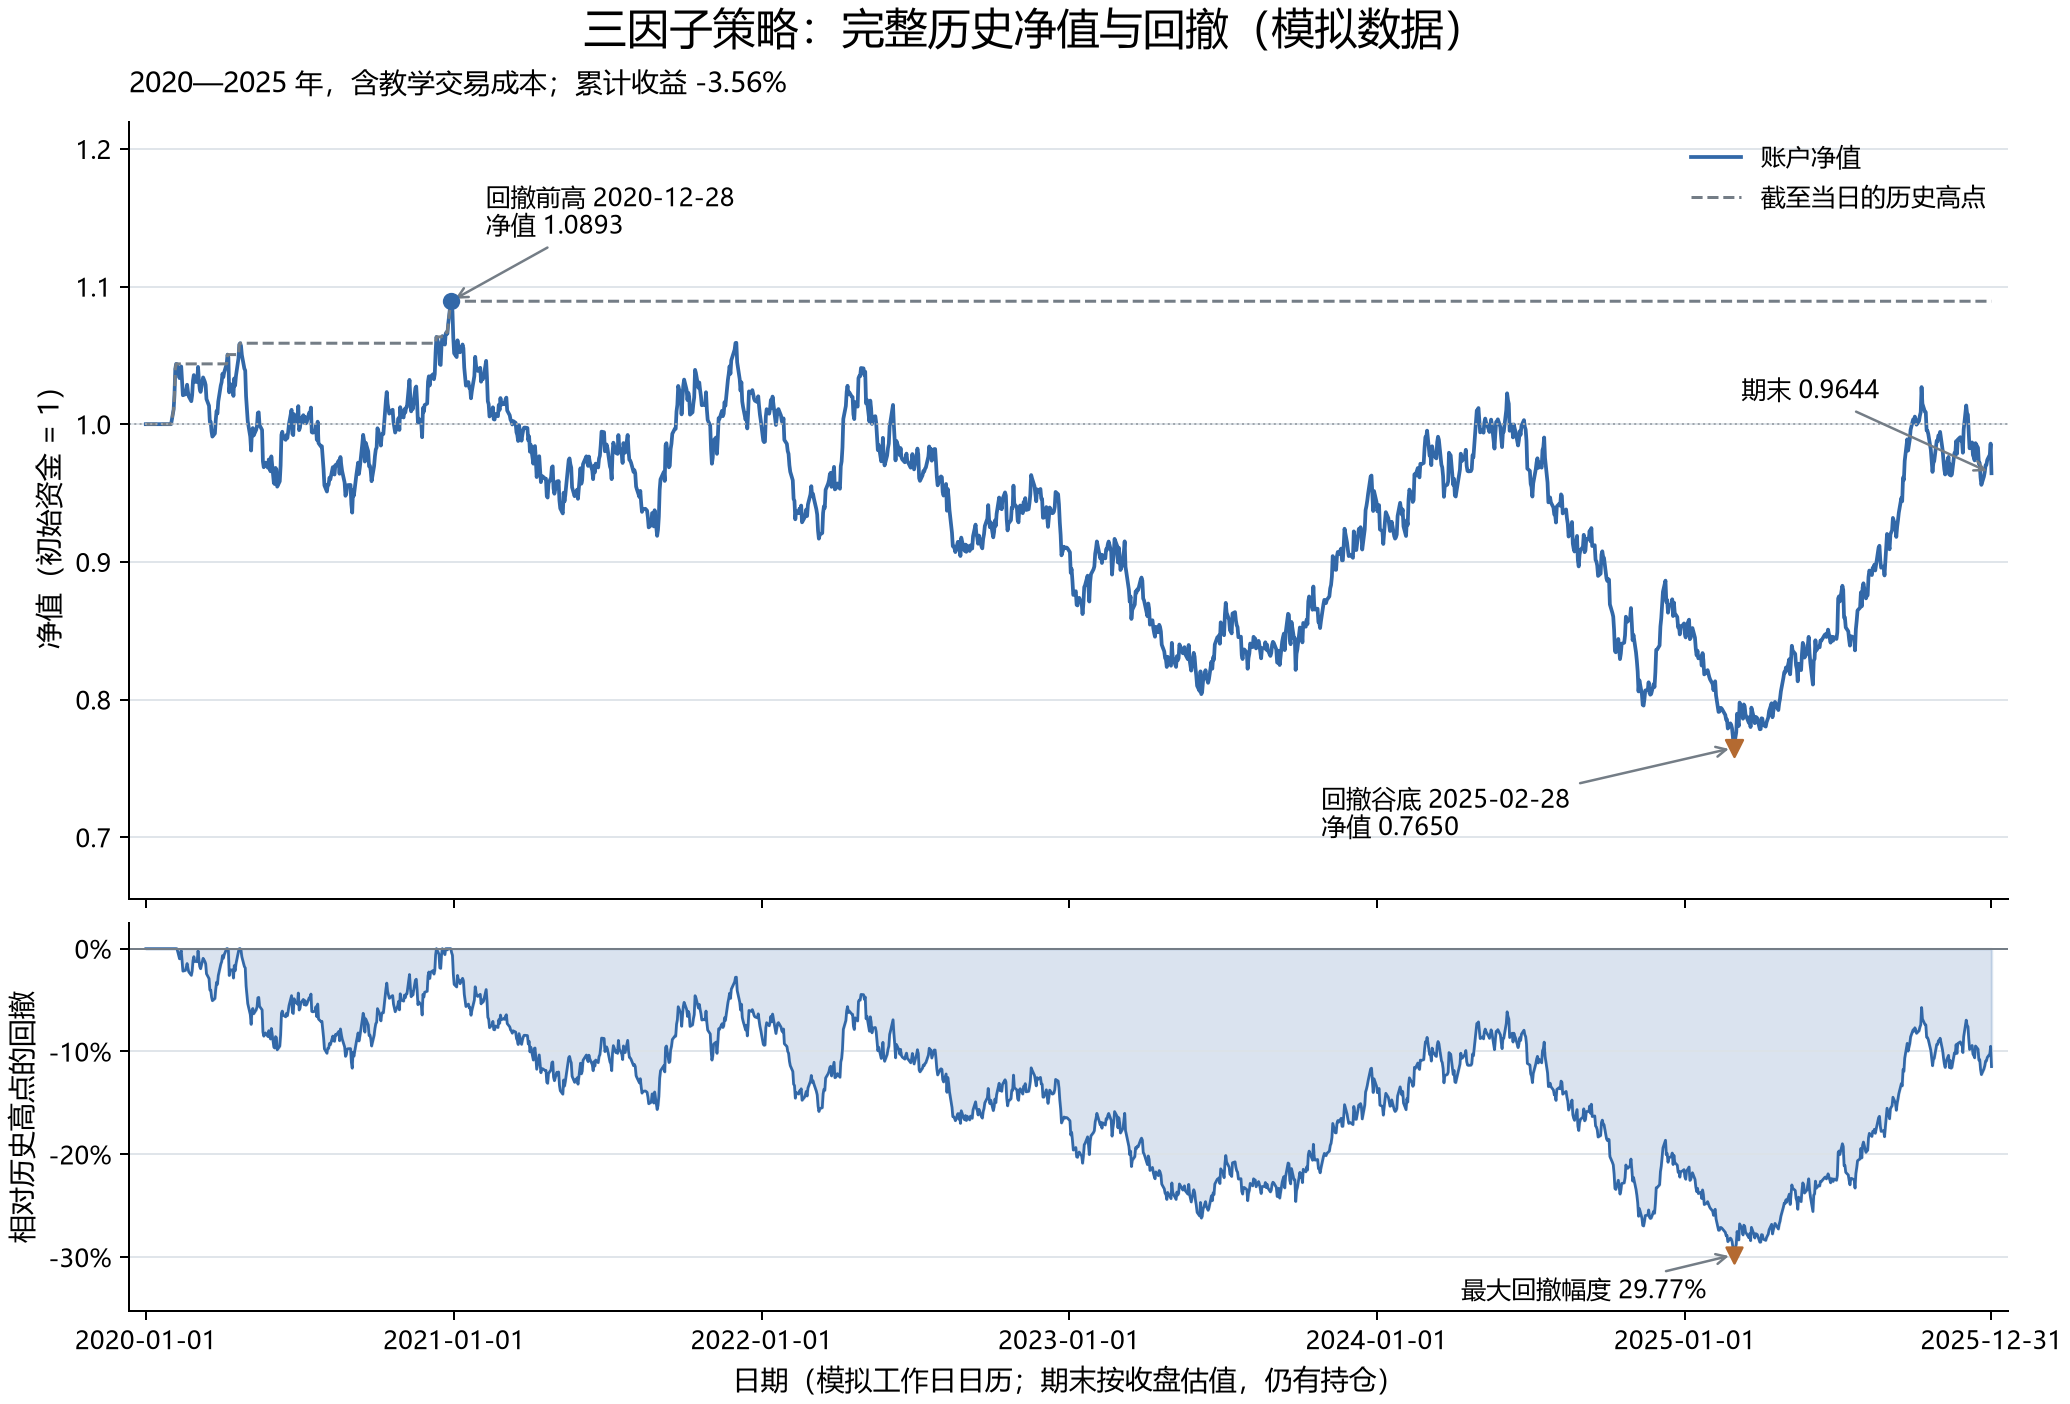

In [7]:
from IPython.display import Image, display
display(Image(filename=str(PROJECT_ROOT / 'runs/first_demo_20261107/lesson15_full_backtest/full_history_nav_drawdown.png')))

## 运行复核

以上实现已在干净内核中按顺序执行；执行状态记录在仓库的 [Notebook 校验记录](../../publication/notebook_validation.json)。代码中的数据身份、费用和成交假设仍然适用，运行成功只验证对应实现。